In [25]:
import sys
print(sys.executable)

/Users/takanohiroshi/myenv/bin/python


# 2.1 連立一次方程式

In [2]:
import pulp
import numpy as np
import matplotlib.pyplot as plt

problem = pulp.LpProblem('SLE', pulp.LpMaximize)

x = problem.add_variable('x', cat="Continuous")
y = problem.add_variable('y', cat="Continuous")

problem += 120*x + 150*y == 1440
problem += x + y == 10

status = problem.solve()

print(status)
print("x =", x.value())
print("y =", y.value())

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/fac255e0fbe94dec8189c1e68f6c1fed-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/fac255e0fbe94dec8189c1e68f6c1fed-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 13 RHS
At line 16 BOUNDS
At line 20 ENDATA
Problem MODEL has 2 rows, 3 columns and 4 elements
Coin0008I MODEL read with 0 errors
Presolve 0 (-2) rows, 0 (-3) columns and 0 (-4) elements
Empty problem - 0 rows, 0 columns and 0 elements
Optimal - objective value 0
After Postsolve, objective 0, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective 0 - 0 iterations time 0.002, Presolve 0.00
Total time (Wallclock seconds): 0.00714493   (CPU seconds):             0.00288
solver: COIN_CMD (Devel)
status: Optimal (1)
has solution: True
objective: None
time: 0.0577s (cp

# 2.2 線形計画問題

In [3]:
import pulp

problem = pulp.LpProblem('SLE', pulp.LpMaximize)

x = problem.add_variable('x', cat="Continuous")
y = problem.add_variable('y', cat="Continuous")

problem += 120*x + 150*y == 1440
problem += x + y == 10

status = problem.solve()

print(status)
print("x =", x.value())
print("y =", y.value())

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/9c376b1c6f5f4c3ea8b3649d8b3a8b04-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/9c376b1c6f5f4c3ea8b3649d8b3a8b04-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 7 COLUMNS
At line 13 RHS
At line 16 BOUNDS
At line 20 ENDATA
Problem MODEL has 2 rows, 3 columns and 4 elements
Coin0008I MODEL read with 0 errors
Presolve 0 (-2) rows, 0 (-3) columns and 0 (-4) elements
Empty problem - 0 rows, 0 columns and 0 elements
Optimal - objective value 0
After Postsolve, objective 0, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective 0 - 0 iterations time 0.002, Presolve 0.00
Total time (Wallclock seconds): 0.000926971   (CPU seconds):             0.00037
solver: COIN_CMD (Devel)
status: Optimal (1)
has solution: True
objective: None
time: 0.0335s (c

In [4]:
problem = pulp.LpProblem('LP', pulp.LpMaximize)

x = problem.add_variable('x', cat="Continuous")
y = problem.add_variable('y', cat="Continuous")

problem += 1*x + 3*y <=30
problem += 2*x + 1*y <=40
problem += x >=0
problem += y >=0
problem.objective = x+2*y

status = problem.solve()

print(status)
print("x =", x.value())
print("y =", y.value())
print('obj', problem.objective.value())

# ソルバーの結果を取得
x_opt = x.value()
y_opt = y.value()
z_opt = problem.objective.value()

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/6822b7af37e14684bad6b74b9b7fd0a1-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/6822b7af37e14684bad6b74b9b7fd0a1-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 9 COLUMNS
At line 18 RHS
At line 23 BOUNDS
At line 26 ENDATA
Problem MODEL has 4 rows, 2 columns and 6 elements
Coin0008I MODEL read with 0 errors
Presolve 2 (-2) rows, 2 (0) columns and 4 (-2) elements
Optimal - objective value -26
After Postsolve, objective -26, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective -26 - 2 iterations time 0.002, Presolve 0.00
Total time (Wallclock seconds): 0.001791   (CPU seconds):             0.00042
solver: COIN_CMD (Devel)
status: Optimal (1)
has solution: True
objective: 26.0
time: 0.0336s (cpu 0.0600s)
x = 18.0
y = 4.0
obj 26.0


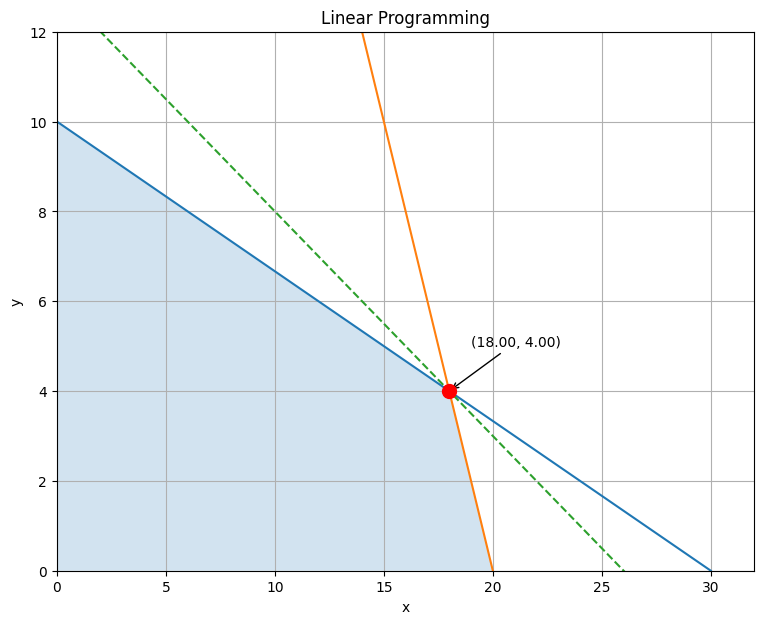

In [5]:
# -----------------------------
# グラフの作成
# -----------------------------

xx = np.linspace(0, 30, 300)

# 制約条件の直線
y1 = (30 - xx) / 3
y2 = 40 - 2 * xx

# 最適解から目的関数の直線を作成
y3 = (z_opt - xx) / 2

plt.figure(figsize=(9, 7))

plt.plot(xx, y1, label='x + 3y = 30')
plt.plot(xx, y2, label='2x + y = 40')

# 実行可能領域
plt.fill(
    [0, 20, 18, 0],
    [0, 0, 4, 10],
    alpha=0.2,
    label='Feasible Region'
)

# 目的関数の直線
plt.plot(xx, y3, '--',
         label=f'x + 2y = {z_opt:.2f}')

# ソルバーが求めた最適解
plt.scatter(x_opt, y_opt, color='red',
            s=100, zorder=5,
            label='Optimal Solution')

plt.annotate(
    f'({x_opt:.2f}, {y_opt:.2f})',
    xy=(x_opt, y_opt),
    xytext=(x_opt + 1, y_opt + 1),
    arrowprops=dict(arrowstyle='->')
)

plt.xlim(0, 32)
plt.ylim(0, 12)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Linear Programming')
plt.grid(True)

In [6]:
import pandas as pd

stock_df = pd.read_csv('stocks.csv')
stock_df.head()

,m,stock
0,m1,35
1,m2,22
2,m3,27


In [7]:
requir_df = pd.read_csv('requires.csv')
requir_df.head()

,p,m,require
0,p1,m1,2
1,p1,m2,0
2,p1,m3,1
3,p2,m1,3
4,p2,m2,2


In [8]:
gain_df = pd.read_csv('gains.csv')
gain_df.head()

,p,gain
0,p1,3
1,p2,4
2,p3,4
3,p4,5


In [9]:
P = gain_df['p'].tolist()
P

['p1', 'p2', 'p3', 'p4']

In [10]:
M = stock_df['m'].tolist()
M

['m1', 'm2', 'm3']

In [11]:
stock = {row.m: row.stock for row in stock_df.itertuples()}

stock

{'m1': 35, 'm2': 22, 'm3': 27}

In [12]:
gain = {row.p: row.gain for row in gain_df.itertuples()}
gain

{'p1': 3, 'p2': 4, 'p3': 4, 'p4': 5}

In [13]:
require = {(row.p, row.m): row.require for row in requir_df.itertuples()}

require

{('p1', 'm1'): 2,
 ('p1', 'm2'): 0,
 ('p1', 'm3'): 1,
 ('p2', 'm1'): 3,
 ('p2', 'm2'): 2,
 ('p2', 'm3'): 0,
 ('p3', 'm1'): 0,
 ('p3', 'm2'): 2,
 ('p3', 'm3'): 2,
 ('p4', 'm1'): 2,
 ('p4', 'm2'): 2,
 ('p4', 'm3'): 2}

In [14]:
problem = pulp.LpProblem('LP2', pulp.LpMaximize)



In [15]:
x = {p:problem.add_variable(f'x_{p}', cat="Continuous") for p in P}
x

{'p1': x_p1, 'p2': x_p2, 'p3': x_p3, 'p4': x_p4}

In [16]:
for p in P:
    problem += x[p] >= 0

for m in M:
    problem += pulp.lpSum([require[p,m]*x[p] for p in P]) <= stock[m]

In [17]:
problem += pulp.lpSum([gain[p]*x[p] for p in P])

problem


LP2:
MAXIMIZE
3.0*x_p1 + 4.0*x_p2 + 4.0*x_p3 + 5.0*x_p4 + 0.0
SUBJECT TO
_C1: x_p1 >= 0

_C2: x_p2 >= 0

_C3: x_p3 >= 0

_C4: x_p4 >= 0

_C5: 2 x_p1 + 3 x_p2 + 2 x_p4 <= 35

_C6: 2 x_p2 + 2 x_p3 + 2 x_p4 <= 22

_C7: x_p1 + 2 x_p3 + 2 x_p4 <= 27

VARIABLES
x_p1 free Continuous
x_p2 free Continuous
x_p3 free Continuous
x_p4 free Continuous

In [18]:
status = problem.solve()
print("Status:", status)
print("Objective value:", pulp.value(problem.objective))

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/7e1e08516a394b17a362b8e9581b265f-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/7e1e08516a394b17a362b8e9581b265f-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 12 COLUMNS
At line 30 RHS
At line 38 BOUNDS
At line 43 ENDATA
Problem MODEL has 7 rows, 4 columns and 13 elements
Coin0008I MODEL read with 0 errors
Presolve 3 (-4) rows, 4 (0) columns and 9 (-4) elements
Optimal - objective value -80.428571
After Postsolve, objective -80.428571, infeasibilities - dual 0 (0), primal 0 (0)
Optimal objective -80.42857143 - 4 iterations time 0.002, Presolve 0.00
Total time (Wallclock seconds): 0.00102901   (CPU seconds):             0.001319
Status: solver: COIN_CMD (Devel)
status: Optimal (1)
has solution: True
objective: 80.42857099999999
time: 0.0379s 

In [19]:
for p in P:
    print(f"x_{p} = {x[p].value()}")

print('obj :', pulp.value(problem.objective.value()))

x_p1 = 12.142857
x_p2 = 3.5714286
x_p3 = 7.4285714
x_p4 = 0.0
obj : 80.42857099999999


In [20]:
problem = pulp.LpProblem('LP3', pulp.LpMaximize)

x = {p:problem.add_variable(f'x_{p}', cat="Integer") for p in P}
x

{'p1': x_p1, 'p2': x_p2, 'p3': x_p3, 'p4': x_p4}

In [21]:
for p in P:
    problem += x[p] >= 0

for m in M:
    problem += pulp.lpSum([require[p,m]*x[p] for p in P]) <= stock[m]

In [22]:
problem += pulp.lpSum([gain[p]*x[p] for p in P])

problem


LP3:
MAXIMIZE
3.0*x_p1 + 4.0*x_p2 + 4.0*x_p3 + 5.0*x_p4 + 0.0
SUBJECT TO
_C1: x_p1 >= 0

_C2: x_p2 >= 0

_C3: x_p3 >= 0

_C4: x_p4 >= 0

_C5: 2 x_p1 + 3 x_p2 + 2 x_p4 <= 35

_C6: 2 x_p2 + 2 x_p3 + 2 x_p4 <= 22

_C7: x_p1 + 2 x_p3 + 2 x_p4 <= 27

VARIABLES
x_p1 free Integer
x_p2 free Integer
x_p3 free Integer
x_p4 free Integer

In [23]:
status = problem.solve()
print("Status:", status)
print("Objective value:", pulp.value(problem.objective))

Welcome to the CBC MILP Solver
Version: Devel (unstable)
Build Date: Mar 23 2026
command line - /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/b30eb310db554cab9ea16155abc70c4a-pulp.mps -timeMode elapsed -solve -printingOptions all -solution /var/folders/52/k1p3ltss0cx1z00jsbnh_2xr0000gn/T/b30eb310db554cab9ea16155abc70c4a-pulp.sol (default strategy 1)
At line 2 NAME          MODEL
At line 3 ROWS
At line 12 COLUMNS
At line 38 RHS
At line 46 BOUNDS
At line 51 ENDATA
Problem MODEL has 7 rows, 4 columns and 13 elements
Coin0008I MODEL read with 0 errors
Continuous objective value is -80.4286 - 0.000691 seconds
Cgl0004I processed model has 3 rows, 4 columns (4 integer (0 of which binary)) and 9 elements
Coin0011I Conflict graph built in 0.001 seconds, density: 0.000%
Cgl0015I Clique Strengthening extended 0 cliques, 0 were dominated
Cbc0045I Nauty did not find any useful orbits in time 0.000369
Cbc0012I Integer solution of -77 found by DiveCoefficient after 0 iterations and 0 nodes (0.01 s

In [24]:
for p in P:
    print(f"x_{p} = {x[p].value()}")

print('obj :', pulp.value(problem.objective.value()))

x_p1 = 13.0
x_p2 = 3.0
x_p3 = 7.0
x_p4 = 0.0
obj : 79.0
